# Corrected physical Blending Tank

A conservation-law implementation with explicitly declared parameters. State order: `[X,V]`; input order: `[w1,w2,x1,x2,wout]`. Time is in minutes, mass flows in kg/min, volume in m³, and fractions are dimensionless. Density 1000 kg/m³ is an explicit study assumption.

[Derivation and usage](README.md) · [Validation evidence](VALIDATION.md)

## Prepare the environment

In Colab, the following cell downloads the public course repository and installs its declared numerical requirements. Locally it uses the existing checkout.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## 1. Establish a genuine equilibrium

The default inlets carry 500 and 200 kg/min, with solute fractions 0.4 and 0.75. Equilibrium requires outlet 700 kg/min and gives tank fraction 0.5. The chosen equilibrium volume is 2 m³. Inspect the analytical Jacobian and reduced transfer functions. They map deviations from these operating values.

In [2]:
import json
import numpy as np
from intelligent_control.physical_blending import DEFAULT_INPUT, DEFAULT_STATE, linearize, transfer_functions, equilibrium, jacobians, rhs, simulate
model = linearize()
print("Equilibrium state:", model["x_eq"])
print("Equilibrium input:", model["u_eq"])
print("A:\n", model["A"])
print("B:\n", model["B"])
print(json.dumps(transfer_functions(), indent=2))

Equilibrium state: [0.5 2. ]
Equilibrium input: [5.0e+02 2.0e+02 4.0e-01 7.5e-01 7.0e+02]
A:
 [[-3.50000000e-01 -3.55271368e-18]
 [ 0.00000000e+00  0.00000000e+00]]
B:
 [[-5.00e-05  1.25e-04  2.50e-01  1.00e-01  0.00e+00]
 [ 1.00e-03  1.00e-03  0.00e+00  0.00e+00 -1.00e-03]]
{
  "X/w1": {
    "numerator": [
      -4.999999999999999e-05
    ],
    "denominator": [
      1.0,
      0.35000000000000003
    ]
  },
  "X/w2": {
    "numerator": [
      0.000125
    ],
    "denominator": [
      1.0,
      0.35000000000000003
    ]
  },
  "X/x1": {
    "numerator": [
      0.25
    ],
    "denominator": [
      1.0,
      0.35000000000000003
    ]
  },
  "X/x2": {
    "numerator": [
      0.1
    ],
    "denominator": [
      1.0,
      0.35000000000000003
    ]
  },
  "X/wout": {
    "numerator": [
      0.0
    ],
    "denominator": [
      1.0
    ]
  },
  "V/w1": {
    "numerator": [
      0.001
    ],
    "denominator": [
      1.0,
      0.0
    ]
  },
  "V/w2": {
    "numerator": [
   

## 2. Run startup, filling and a local perturbation

Startup uses zero initial solute and balanced flow. Filling keeps outlet 650 kg/min and compares with its variable-volume closed form. The perturbation starts at equilibrium and adds 10 kg/min to inlet 1 at minute 5. Its linear branch propagates input/state deviations and restores the output offsets. The linear approximation is assessed only as a local model.

In [3]:
import runpy
study = runpy.run_path(str(ROOT / "blending-tank/run_study.py"))
result = study["run_study"](ROOT / "blending-tank/results")
print(json.dumps(result["summary"]["scenarios"], indent=2))

{
  "balanced_startup": {
    "initial_state": [
      0.0,
      2.0
    ],
    "constant_input": [
      500.0,
      200.0,
      0.4,
      0.75,
      700.0
    ],
    "final_state": [
      0.4999862317753249,
      2.0
    ],
    "max_concentration_error_vs_closed_form": 3.319566843629218e-14,
    "max_volume_error_vs_closed_form_m3": 0.0,
    "solute_balance_final_residual_kg": -1.1368683772161603e-13
  },
  "filling_outlet_650": {
    "initial_state": [
      0.0,
      2.0
    ],
    "constant_input": [
      500.0,
      200.0,
      0.4,
      0.75,
      650.0
    ],
    "final_state": [
      0.499802103860259,
      3.5000000000000036
    ],
    "max_concentration_error_vs_closed_form": 2.8976820942716586e-14,
    "max_volume_error_vs_closed_form_m3": 5.773159728050814e-15,
    "solute_balance_final_residual_kg": 1.3642420526593924e-12
  },
  "local_flow_step": {
    "initial_state": [
      0.5,
      2.0
    ],
    "step_time_min": 5.0,
    "w1_step_kg_per_min": 10.0,


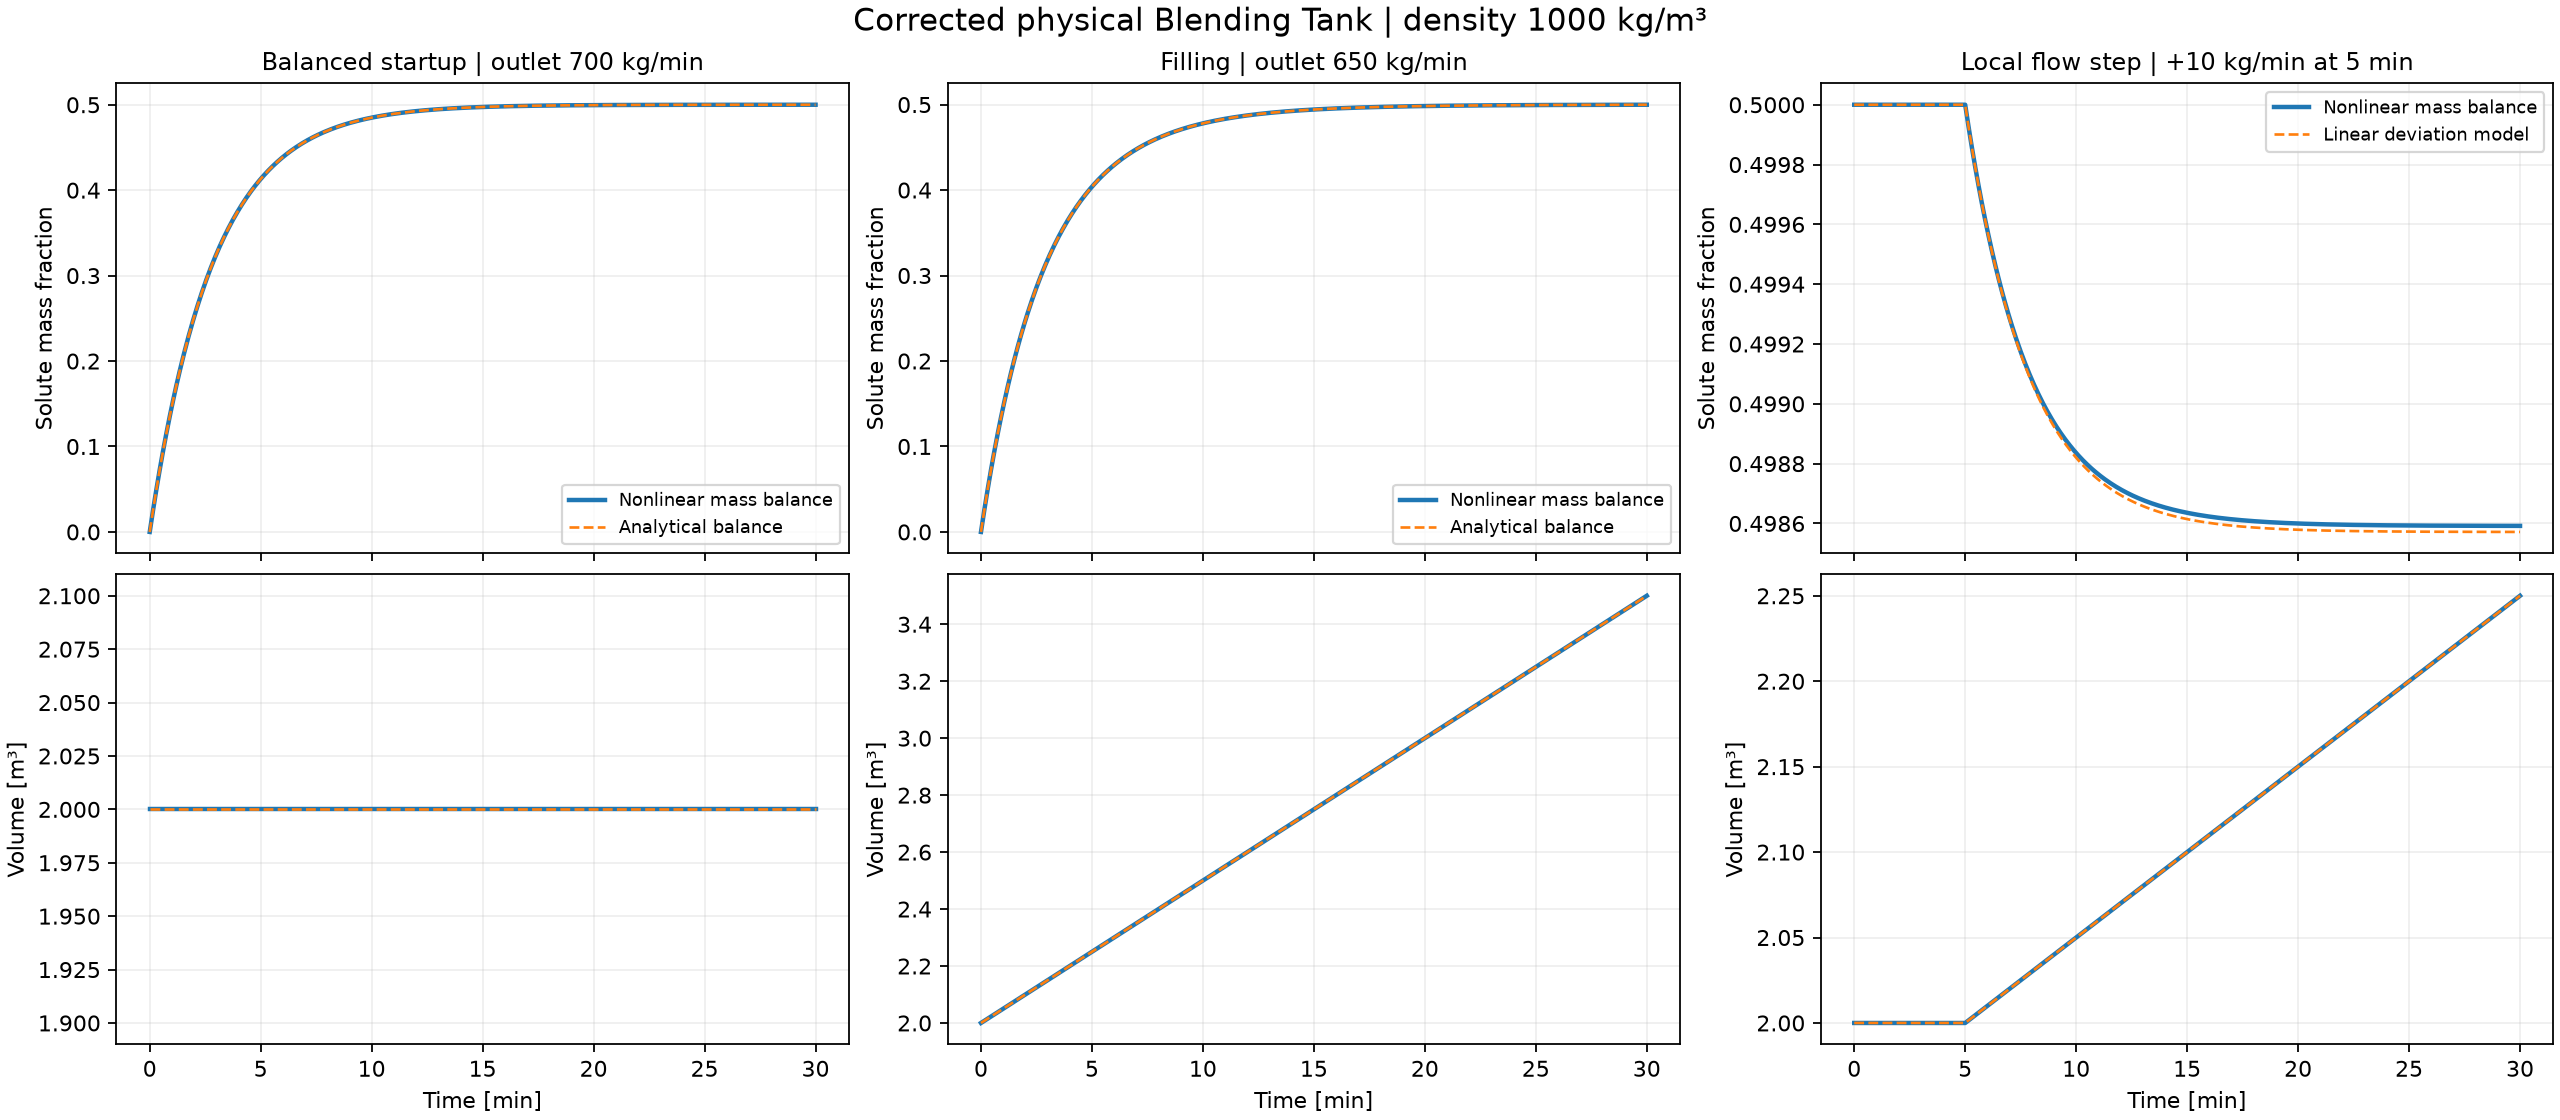

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "blending-tank/results/comparison.png")))

## 3. Distinguish filling from equilibrium

An outlet of 650 kg/min is a valid filling experiment. It cannot define a full constant-volume equilibrium with the stated inlets. Away from equilibrium, retain the affine drift term and the volume derivative of the concentration balance.

In [5]:
filling_input = DEFAULT_INPUT.copy()
filling_input[4] = 650.
try:
    equilibrium(filling_input)
except ValueError as error:
    print("Equilibrium rejected as expected:", error)
reference_state = np.array([.3, 2.])
A_local, B_local = jacobians(reference_state, filling_input)
print("Nonzero affine drift:", rhs(reference_state, filling_input))
print("General A(1,2):", A_local[0, 1])

Equilibrium rejected as expected: Equilibrium volume requires wout = w1+w2
Nonzero affine drift: [0.07 0.05]
General A(1,2): -0.035


## 4. Reject a requested run through an empty tank

Known piecewise-constant flows give an exact volume forecast. The numerical interface checks the full requested horizon before integrating. It does not silently continue through zero volume or clip the physical equations.

In [6]:
draining_input = DEFAULT_INPUT.copy()
draining_input[4] = 900.
try:
    simulate(DEFAULT_STATE, np.linspace(0., 20., 41), draining_input)
except ValueError as error:
    print("Invalid simulation horizon rejected as expected:", error)

Invalid simulation horizon rejected as expected: Planned trajectory reaches minimum_volume; shorten the horizon or change flows


## Inspect and extend

1. Explain the negative transfer gain from the dilute inlet to tank fraction.
2. Halve the inlet-flow perturbation and compare local linearization errors.
3. Change density explicitly and regenerate both the nonlinear and linear models.
4. Explain why the volume pole is an integrator and why outlet flow has no direct first-order effect on concentration at equilibrium.
5. Compare the MATLAB/Octave equations with these results. Generate the fresh Simulink diagrams only in MATLAB with Simulink.

The numerical tests establish consistency with the stated ideal model. No measured-tank validation or proprietary-runtime execution is implied.